<img src="https://raw.githubusercontent.com/drdave-teaching/OPIM5509-notebooks/main/_banners/opim5509_banner.svg" width="100%" alt="OPIM 5509 banner"/>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/drdave-teaching/OPIM5509-notebooks/blob/main/FinalProject/FP1b_Tune_Your_LSTM.ipynb)

# Final Project, Part 1b: Tune Your LSTM (then ship the winner)
--------------------------------------------------
**Dr. Dave Wanik - University of Connecticut**

Your basic LSTM from Part 1 is live. Now make it better. You'll tune in **rounds**: try a grid of networks (different
layers, a convolution and pooling in front, different sizes, GRU or LSTM, dropout), see what helped, and push further
in that direction. Every network lands on your own **tuning leaderboard**, ranked on **2025**, the validation year.
Only the winner gets to see **2026**, the holdout year. If it beats your Part 1 model, ship it.

The data, the inputs (`make_inputs`) and the train / validation / test split are copied **word for word** from Part 1,
so every network here sees exactly what the cloud function will give it.

**Keras models only.** Every network here is a Keras model, and whatever you ship must be one too (no scikit-learn,
gradient boosting, random or quantile forests, or XGBoost in production).

| Part | What | Time (T4 GPU) |
| :-- | :-- | --: |
| 0 | Before you start | 2 min |
| 1 | Load the data | 1 min |
| 2 | The same inputs and split as Part 1 | 2 min |
| 3 | The baseline to beat | 1 min |
| 4 | Tuning in rounds: your own leaderboard, picked on 2025 | 15+ min |
| 5 | The champion on 2026 (the holdout) | 2 min |
| 6 | Look at it: actual vs. predicted, and the holdout over time | 5 min |
| 7 | Save it for the cloud | 1 min |
| 8 | Ship the winner | 5 min |

## Part 0 · Before you start
**Runtime > Change runtime type > T4 GPU.** Each network takes about a minute on a GPU (much longer on a CPU), and
Rounds 1 and 2 train 12 of them.

In [1]:
import json
import time

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from keras import layers
from pandas.tseries.holiday import USFederalHolidayCalendar

SETTINGS = {
    "seed": 5509,
    "lookback_hours": 168,          # the LSTM reads the past week of load, one hour at a time
    "horizon_hours": 24,            # and forecasts the next 24 hours
    "valid_start_utc": "2025-01-01",  # train on 2023-2024
    "test_start_utc": "2026-01-01",   # validate on 2025 (early stopping), test on 2026 (data the model never saw)
    "units": 64,
    "epochs": 30,
    "batch_size": 128,
    "patience": 3,
}

keras.utils.set_random_seed(SETTINGS["seed"])
tf.config.experimental.enable_op_determinism()
print("Keras", keras.__version__, "| GPU:", len(tf.config.list_physical_devices("GPU")) > 0)

Keras 3.15.1 | GPU: False


## Part 1 · Load the data
One row per hour from January 2023 to October 2026: Connecticut's electricity load (`load_mw`, from ISO New England)
and the weather at Bradley airport. It is the same file the OPIM 5512 class uses. All times are in UTC (`hour_utc` =
the hour the value begins), so daylight saving never duplicates or drops a row.

**Training vs. the cloud.** You train on this history file once. After that, nobody downloads anything: the functions
in your energy project (from the setup guide) collect the same inputs every hour on their own.

| Input | In training (this file) | In the cloud, every hour |
| :-- | :-- | :-- |
| Past week of load | ISO New England's metered Connecticut load | your `scraper-isone` (ISO New England's live five-minute load, averaged per hour) |
| Next 24 hours of weather | the weather that actually happened at Bradley | Dr. Dave's class file of HRRR weather forecasts for Bradley; if it is ever missing, the National Weather Service forecast your `scraper-weather-forecast` saves from forecast.weather.gov |
| Calendar (hour, day of week, time of year, weekend, holiday) | computed from the clock | computed from the clock |

In [2]:
URL = "https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/Module4/data/bdl_ct_load_hourly_2023_2026.csv"
df = pd.read_csv(URL, parse_dates=["hour_utc"])
df = df.set_index("hour_utc").sort_index()

# make every hour exist, so "168 rows back" always means "168 hours back"
all_hours = pd.date_range(df.index.min(), df.index.max(), freq="h")
df = df.reindex(all_hours)
print(df.shape, "| from", df.index.min(), "to", df.index.max())
print("hours with no load:", int(df["load_mw"].isna().sum()))
df[["load_mw", "temp_f", "dewpoint_f", "rel_humidity_pct", "wind_speed_mph", "cloud_cover_pct"]].describe().round(1)

(33215, 17) | from 2023-01-01 05:00:00+00:00 to 2026-10-16 03:00:00+00:00
hours with no load: 0


,load_mw,temp_f,dewpoint_f,rel_humidity_pct,wind_speed_mph,cloud_cover_pct
count,33215.0,33215.0,33215.0,33215.0,33215.0,33215.0
mean,3062.8,53.6,41.3,66.3,7.4,61.4
std,686.9,18.7,19.0,20.1,5.1,34.9
min,1682.7,-9.0,-29.0,9.6,0.0,0.0
25%,2569.7,39.0,27.0,50.6,4.6,19.0
50%,2965.8,54.0,43.0,67.0,6.9,75.0
75%,3438.9,69.0,57.0,84.2,10.4,100.0
max,6485.8,99.0,78.0,100.0,34.5,100.0


## Part 2 · The same inputs and split as Part 1
At **issue hour T** (the hour the forecast is made), the model gets two inputs and makes one output:

* **The past:** the 168 hours before T - the load plus the hour of the day (as a sine and a cosine, so 11 PM sits
  next to midnight). Shape `(168, 3)`.
* **The future it is told about:** the 24 hours from T+1 to T+24 - the weather forecast for those hours plus the
  calendar (hour of day, day of week, time of year, weekend, holiday). Shape `(24, 13)`.
* **The answer:** the load for those 24 hours. Shape `(24,)`.

In training we use the weather that actually happened as the "forecast". In the cloud the model gets a real
forecast, which is less accurate - Part 2 deals with that.

Everything is **scaled** with means and standard deviations from the training years only, and those numbers are saved
with the model, so the cloud scales new data exactly the same way.

`make_inputs` below is the **contract** between this notebook and the cloud: the cloud function runs this exact code.
If you change it (new features, a longer look-back), you change it there too.

In [3]:
WEATHER = ["temp_f", "dewpoint_f", "rel_humidity_pct", "wind_speed_mph", "cloud_cover_pct"]
HOLIDAYS = USFederalHolidayCalendar().holidays(start="2020-01-01", end="2030-12-31")


def calendar_features(hours_utc):
    """Hour of day, day of week and time of year as sines and cosines, plus weekend and holiday flags, in Connecticut time."""
    local = pd.DatetimeIndex(hours_utc).tz_convert("America/New_York")
    out = pd.DataFrame(index=pd.DatetimeIndex(hours_utc))
    out["hour_sin"] = np.sin(2 * np.pi * local.hour / 24)
    out["hour_cos"] = np.cos(2 * np.pi * local.hour / 24)
    out["dow_sin"] = np.sin(2 * np.pi * local.dayofweek / 7)
    out["dow_cos"] = np.cos(2 * np.pi * local.dayofweek / 7)
    out["doy_sin"] = np.sin(2 * np.pi * local.dayofyear / 365.25)
    out["doy_cos"] = np.cos(2 * np.pi * local.dayofyear / 365.25)
    out["is_weekend"] = (local.dayofweek >= 5).astype(float)
    out["is_holiday"] = local.tz_localize(None).normalize().isin(HOLIDAYS).astype(float)
    return out


def make_inputs(issue_hour_utc, load, weather, card):
    """The model's two inputs for ONE forecast issued at issue_hour_utc.
    load: Connecticut load in MW indexed by UTC hour (only hours that are over).
    weather: the WEATHER columns indexed by UTC hour, covering the next 24 hours.
    card: the model card (look-back, horizon and the scaling numbers).
    Returns past (lookback, 3) and future (horizon, 13), both scaled."""
    issue = pd.Timestamp(issue_hour_utc)
    past_hours = pd.date_range(issue - pd.Timedelta(hours=card["lookback_hours"]), periods=card["lookback_hours"], freq="h")
    future_hours = pd.date_range(issue + pd.Timedelta(hours=1), periods=card["horizon_hours"], freq="h")
    past_load = (load.reindex(past_hours).values - card["load_mean"]) / card["load_std"]
    past_cal = calendar_features(past_hours)[["hour_sin", "hour_cos"]].values
    past = np.column_stack([past_load, past_cal])
    future_weather = weather[WEATHER].reindex(future_hours)
    scaled_weather = []
    for column in WEATHER:
        scaled_weather.append((future_weather[column].values - card["weather_mean"][column]) / card["weather_std"][column])
    future = np.column_stack(scaled_weather + [calendar_features(future_hours).values])
    return past.astype("float32"), future.astype("float32")

Now one sample per issue hour (an hour is kept only if its whole past week and its next 24 hours exist), split into
blocks of time.

**Train, validation and test: three blocks of time, in order.**

| Block | Years | Used for |
| :-- | :-- | :-- |
| train | 2023-2024 | `model.fit` learns from these (`X_past_train`, `X_future_train`, `y_train`) |
| validation | 2025 | early stopping watches these to decide when to stop (`..._valid`) |
| test | 2026 | scored once, at the very end, like a brand-new year (`..._test`) |

Three rules keep the test honest (no **data leakage**):
1. **Never a random split.** Hour 5 PM and hour 6 PM look almost the same, so a random split would hide near-copies of
   test hours in the training set and the score would look far better than it really is. Time series split by time.
2. **Scaling numbers come from the training years only.** The mean and standard deviation that scale every input are
   computed on 2023-2024, then reused for 2025, 2026 and the cloud.
3. **No target hour in two blocks.** A forecast issued on the evening of Dec 31, 2024 predicts hours in 2025, so it
   is dropped. Its past week may reach back into the block before, and that's fine: the past is known when you forecast.

One honest caveat: these inputs use the weather that **actually happened**, which no forecaster knows in advance.
That makes the 2026 score optimistic; Part 2 (Part 6) re-tests with the weather forecasts the model would really have.

In [4]:
# Three time blocks, in order. Never a random split for a time series: neighboring hours are almost identical, so a
# random split would put near-copies of the test hours into training and the score would look much better than it is.
valid_start = pd.Timestamp(SETTINGS["valid_start_utc"], tz="UTC")     # 2025 = validation (early stopping watches it)
test_start = pd.Timestamp(SETTINGS["test_start_utc"], tz="UTC")       # 2026 = test (used once, at the very end)
# The scaling numbers come from the TRAINING hours only, so nothing from 2025 or 2026 leaks into the inputs
is_train_hour = df.index < valid_start
card = {
    "model_type": "keras_lstm",
    "lookback_hours": SETTINGS["lookback_hours"],
    "horizon_hours": SETTINGS["horizon_hours"],
    "weather_columns": WEATHER,
    "load_mean": float(df.loc[is_train_hour, "load_mw"].mean()),
    "load_std": float(df.loc[is_train_hour, "load_mw"].std()),
    "weather_mean": {},
    "weather_std": {},
}
for column in WEATHER:
    card["weather_mean"][column] = float(df.loc[is_train_hour, column].mean())
    card["weather_std"][column] = float(df.loc[is_train_hour, column].std())

load = df["load_mw"]
weather = df[WEATHER]
lookback = SETTINGS["lookback_hours"]
horizon = SETTINGS["horizon_hours"]

start = time.time()
# make_inputs builds ONE forecast. For 33,000 training samples it is much faster to build the same numbers for every
# hour at once, slide a window over them, and then check a few samples against make_inputs (the code the cloud runs).
hours = df.index
load_scaled = (load.values - card["load_mean"]) / card["load_std"]
scaled_weather = []
for column in WEATHER:
    scaled_weather.append((weather[column].values - card["weather_mean"][column]) / card["weather_std"][column])
calendar = calendar_features(hours)
every_hour_past = np.column_stack([load_scaled, calendar[["hour_sin", "hour_cos"]].values]).astype("float32")
every_hour_future = np.column_stack(scaled_weather + [calendar.values]).astype("float32")

windows_past = np.lib.stride_tricks.sliding_window_view(every_hour_past, lookback, axis=0)        # window k = hours k ... k+167
windows_future = np.lib.stride_tricks.sliding_window_view(every_hour_future, horizon, axis=0)    # window k = hours k ... k+23
windows_load = np.lib.stride_tricks.sliding_window_view(load_scaled.astype("float32"), horizon)
issue_positions = np.arange(lookback, len(hours) - horizon)
past_all = windows_past[issue_positions - lookback].transpose(0, 2, 1)        # the 168 hours before the issue hour (T-168 ... T-1)
future_all = windows_future[issue_positions + 1].transpose(0, 2, 1)           # the 24 hours after it (T+1 ... T+24): weather + calendar, no load
y_all = windows_load[issue_positions + 1]                                       # the answer: load at T+1 ... T+24 (never inside an input)
missing = np.isnan(past_all).any(axis=(1, 2)) | np.isnan(future_all).any(axis=(1, 2)) | np.isnan(y_all).any(axis=1)
X_past = np.ascontiguousarray(past_all[~missing])
X_future = np.ascontiguousarray(future_all[~missing])
y = np.ascontiguousarray(y_all[~missing])
issue_hours = hours[issue_positions[~missing]]
# Each sample's 24 target hours must sit inside ONE block. A forecast issued at 8 PM on Dec 31, 2024 predicts hours in
# 2025, so it belongs to neither block and is dropped (the same at the 2025/2026 line): no target hour is in two blocks.
# (Its PAST week may reach back into the block before; that's fine, because the past is known when you forecast.)
last_target = issue_hours + pd.Timedelta(hours=horizon)
train = last_target < valid_start
valid = (issue_hours >= valid_start) & (last_target < test_start)
test = issue_hours >= test_start

# the check: 5 random samples, built the slow way with make_inputs, must match
rng = np.random.default_rng(SETTINGS["seed"])
for k in rng.choice(len(y), 5, replace=False):
    past, future = make_inputs(issue_hours[k], load, weather, card)
    if not (np.allclose(past, X_past[k], atol=1e-5) and np.allclose(future, X_future[k], atol=1e-5)):
        raise ValueError("The fast sequences do not match make_inputs at " + str(issue_hours[k]))
print("5 random samples match make_inputs exactly")
X_past_train = X_past[train]
X_future_train = X_future[train]
y_train = y[train]
X_past_valid = X_past[valid]
X_future_valid = X_future[valid]
y_valid = y[valid]
X_past_test = X_past[test]
X_future_test = X_future[test]
y_test = y[test]
issue_hours_test = issue_hours[test]
blocks = []
for name, mask in [("train", train), ("validation", valid), ("test", test)]:
    first_target = issue_hours[mask].min() + pd.Timedelta(hours=1)
    last_one = last_target[mask].max()
    blocks.append({"block": name, "samples": int(mask.sum()), "first target hour (UTC)": str(first_target)[:16],
                   "last target hour (UTC)": str(last_one)[:16]})
print(f"built in {time.time() - start:.0f} s |", int((~train & ~valid & ~test).sum()), "samples dropped at the block edges")
print("X_past_train", X_past_train.shape, "| X_future_train", X_future_train.shape, "| y_train", y_train.shape)
pd.DataFrame(blocks)

5 random samples match make_inputs exactly
built in 0 s | 48 samples dropped at the block edges
X_past_train (17347, 168, 3) | X_future_train (17347, 24, 13) | y_train (17347, 24)


,block,samples,first target hour (UTC),last target hour (UTC)
0,train,17347,2023-01-08 06:00,2024-12-31 23:00
1,validation,8736,2025-01-01 01:00,2025-12-31 23:00
2,test,6892,2026-01-01 01:00,2026-10-16 03:00


**What goes into the model, column by column.** Two inputs, 16 columns in all. Every number is scaled (training years
only) before the LSTM sees it.

In [5]:
past_columns = ["load_mw", "hour_sin", "hour_cos"]
future_columns = WEATHER + list(calendar.columns)
if len(past_columns) != X_past_train.shape[2] or len(future_columns) != X_future_train.shape[2]:
    raise ValueError("The column lists do not match the arrays")
what = {"load_mw": "Connecticut load (MW)", "hour_sin": "hour of day (sine)", "hour_cos": "hour of day (cosine)",
        "temp_f": "temperature (F)", "dewpoint_f": "dew point (F)", "rel_humidity_pct": "relative humidity (%)",
        "wind_speed_mph": "wind speed (mph)", "cloud_cover_pct": "cloud cover (%)",
        "dow_sin": "day of week (sine)", "dow_cos": "day of week (cosine)",
        "doy_sin": "time of year (sine)", "doy_cos": "time of year (cosine)",
        "is_weekend": "1 on Saturday and Sunday", "is_holiday": "1 on a US federal holiday"}
rows = []
for column in past_columns:
    rows.append({"input": "past (the 168 hours before the issue hour)", "column": column, "what it is": what[column]})
for column in future_columns:
    rows.append({"input": "future (the 24 hours being forecast)", "column": column, "what it is": what[column]})
print("past input:  ", X_past_train.shape[1], "hours x", len(past_columns), "columns")
print("future input:", X_future_train.shape[1], "hours x", len(future_columns), "columns")
print("target:      ", y_train.shape[1], "hours of load_mw")
pd.DataFrame(rows)

past input:   168 hours x 3 columns
future input: 24 hours x 13 columns
target:       24 hours of load_mw


,input,column,what it is
0,past (the 168 hours before the issue hour),load_mw,Connecticut load (MW)
1,past (the 168 hours before the issue hour),hour_sin,hour of day (sine)
2,past (the 168 hours before the issue hour),hour_cos,hour of day (cosine)
3,future (the 24 hours being forecast),temp_f,temperature (F)
4,future (the 24 hours being forecast),dewpoint_f,dew point (F)
5,future (the 24 hours being forecast),rel_humidity_pct,relative humidity (%)
6,future (the 24 hours being forecast),wind_speed_mph,wind speed (mph)
7,future (the 24 hours being forecast),cloud_cover_pct,cloud cover (%)
8,future (the 24 hours being forecast),hour_sin,hour of day (sine)
9,future (the 24 hours being forecast),hour_cos,hour of day (cosine)


## Part 3 · The baseline to beat
**Same hour yesterday**: the load at 5 PM tomorrow will be about what it was at 5 PM today. It costs nothing, and it
is the yardstick the leaderboard uses. The leaderboard splits every forecast into four **lead blocks** (1-6, 7-12,
13-18 and 19-24 hours ahead) and averages them.

In [6]:
def mae_by_block(errors):
    """Mean absolute error for each lead block, from an array of absolute errors shaped (samples, 24)."""
    blocks = {"1-6 h": slice(0, 6), "7-12 h": slice(6, 12), "13-18 h": slice(12, 18), "19-24 h": slice(18, 24)}
    out = {}
    for name in blocks:
        out[name] = float(errors[:, blocks[name]].mean())
    return out


actual_test = y_test * card["load_std"] + card["load_mean"]
baseline_test = []
for issue in issue_hours_test:
    target_hours = pd.date_range(issue + pd.Timedelta(hours=1), periods=horizon, freq="h")
    baseline_test.append(load.reindex(target_hours - pd.Timedelta(hours=24)).values)
baseline_test = np.array(baseline_test)
baseline_blocks = mae_by_block(np.abs(baseline_test - actual_test))
print("same hour yesterday, 2026, average error by lead block (MW):")
for name in baseline_blocks:
    print(f"   {name}: {baseline_blocks[name]:.0f}")

same hour yesterday, 2026, average error by lead block (MW):
   1-6 h: 266
   7-12 h: 266
   13-18 h: 266
   19-24 h: 266


## Part 4 · Tuning in rounds
Tuning is exploring: you try a few networks, see what helped, and go look in that direction. Every network you try,
in every round, lands on **your tuning leaderboard**, ranked by its **average error on 2025** (MW), the validation year.
When a network beats the best so far, you'll see **NEW BEST**.

The rule of the game: you choose with **2025 only**. 2026 is the final exam, opened once in Part 5.

`build_network` is the Part 1 network with five **knobs** (hyperparameters):

| Knob | What it changes |
| :-- | :-- |
| `conv_filters` | 0 = none. More than 0 = a `Conv1D` (that many filters, 3 hours wide) and a `MaxPooling1D` (pool size 2) in front of the first recurrent layer: the convolution picks up short patterns in the past week, and pooling halves its 168 hours to 84 steps, so the next layer reads a shorter, smoother sequence |
| `past_layers` | how many recurrent layers read the past week (2 or more = stacked, `return_sequences=True` on all but the last) |
| `units` | the size of every recurrent layer |
| `cell` | `"LSTM"` or `"GRU"` (a GRU is a lighter LSTM: fewer weights, often just as good) |
| `dropout` | the share of inputs dropped at random while training each recurrent layer (0.0 = none), to fight overfitting |

In [7]:
import itertools

RECURRENT = {"LSTM": layers.LSTM, "GRU": layers.GRU}


def build_network(conv_filters, past_layers, units, cell, dropout):
    """The Part 1 network with five knobs. Same two inputs, same output: the next 24 hours of load (scaled)."""
    keras.utils.set_random_seed(SETTINGS["seed"])          # same starting weights every time: a fair comparison
    Recurrent = RECURRENT[cell]
    past_in = keras.Input(shape=(lookback, X_past_train.shape[2]), name="past")
    future_in = keras.Input(shape=(horizon, X_future_train.shape[2]), name="future")
    x = past_in
    if conv_filters > 0:
        x = layers.Conv1D(conv_filters, kernel_size=3, padding="same", activation="relu", name="conv")(x)
        x = layers.MaxPooling1D(pool_size=2, name="pool")(x)                 # 168 hours -> 84 steps
    for k in range(past_layers - 1):
        x = Recurrent(units, return_sequences=True, dropout=dropout, name="past_layer_" + str(k + 1))(x)
    summary = Recurrent(units, dropout=dropout, name="read_the_past_week")(x)
    repeated = layers.RepeatVector(horizon)(summary)
    merged = layers.Concatenate()([repeated, future_in])
    sequence = Recurrent(units, return_sequences=True, dropout=dropout, name="read_the_next_24_hours")(merged)
    per_hour = layers.TimeDistributed(layers.Dense(1))(sequence)
    forecast = layers.Reshape((horizon,), name="load_next_24h")(per_hour)
    network = keras.Model(inputs=[past_in, future_in], outputs=forecast)
    network.compile(optimizer="adam", loss="mae")
    return network


def network_name(knobs):
    return (knobs["cell"] + "_conv" + str(knobs["conv_filters"]) + "_layers" + str(knobs["past_layers"]) +
            "_units" + str(knobs["units"]) + "_drop" + str(knobs["dropout"]))


actual_valid = y_valid * card["load_std"] + card["load_mean"]
networks = {}            # every network you trained, by name
histories = {}           # and its loss curve
tuning_log = []          # one row per network, every round
best_valid_mae = None


def try_networks(grid, round_name):
    """Train every combination in the grid, print a line per network, and return your tuning leaderboard."""
    global best_valid_mae
    knob_names = list(grid.keys())
    for values in itertools.product(*grid.values()):
        knobs = dict(zip(knob_names, values))
        name = network_name(knobs)
        if name in networks:
            print(name, "is already on your leaderboard")
            continue
        network = build_network(**knobs)
        early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=SETTINGS["patience"], restore_best_weights=True)
        started = time.time()
        history = network.fit([X_past_train, X_future_train], y_train,                       # 2023-2024
                              validation_data=([X_past_valid, X_future_valid], y_valid),    # 2025
                              epochs=SETTINGS["epochs"],
                              batch_size=SETTINGS["batch_size"],
                              callbacks=[early_stop],
                              verbose=0)
        pred_valid = network.predict([X_past_valid, X_future_valid], verbose=0) * card["load_std"] + card["load_mean"]
        valid_mae = float(np.mean(np.abs(pred_valid - actual_valid)))
        news = ""
        if best_valid_mae is None:
            best_valid_mae = valid_mae
        elif valid_mae < best_valid_mae:
            news = f"   NEW BEST, {best_valid_mae - valid_mae:.1f} MW better than the old best"
            best_valid_mae = valid_mae
        networks[name] = network
        histories[name] = history.history
        row = {"round": round_name, "network": name, "valid_mae_mw (2025)": round(valid_mae, 1),
               "epochs": len(history.history["loss"]), "params": network.count_params(),
               "seconds": round(time.time() - started)}
        row.update(knobs)
        tuning_log.append(row)
        print(f"{name}: {valid_mae:.1f} MW on 2025 ({row['epochs']} epochs, {row['seconds']} s){news}")
    return pd.DataFrame(tuning_log).sort_values("valid_mae_mw (2025)").reset_index(drop=True)


build_network(32, 2, 32, "LSTM", 0.0).summary()        # one network with a convolution, pooling and 2 stacked layers

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ past (InputLayer)   │ (None, 168, 3)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv (Conv1D)       │ (None, 168, 32)   │        320 │ past[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool (MaxPooling1D) │ (None, 84, 32)    │          0 │ conv[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ past_layer_1 (LSTM) │ (None, 84, 32)    │      8,320 │ pool[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ read_the_past_week  │ (None, 32)        │      8,320 │ past_layer_1[0][… │
│ (LSTM)              │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector       │ (None, 24, 32)    │          0 │ read_the_past_we… │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ future (InputLayer) │ (None, 24, 13)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 24, 45)    │          0 │ repeat_vector[0]… │
│ (Concatenate)       │                   │            │ future[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ read_the_next_24_h… │ (None, 24, 32)    │      9,984 │ concatenate[0][0] │
│ (LSTM)              │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed    │ (None, 24, 1)     │         33 │ read_the_next_24… │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ load_next_24h       │ (None, 24)        │          0 │ time_distributed… │
│ (Reshape)           │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 26,977 (105.38 KB)

 Trainable params: 26,977 (105.38 KB)

 Non-trainable params: 0 (0.00 B)

### Round 1: eight networks to get your bearings
Two values for each of three knobs: with and without a convolution, one or two layers reading the past week, small or
medium. 2 x 2 x 2 = 8 networks, about 10 minutes on a GPU. Your Part 1 network is one of them
(`LSTM_conv0_layers1_units64_drop0.0`), so you'll see right away whether anything beats it.

In [8]:
ROUND_1 = {
    "conv_filters": [0, 32],
    "past_layers": [1, 2],
    "units": [32, 64],
    "cell": ["LSTM"],
    "dropout": [0.0],
}
leaderboard = try_networks(ROUND_1, "round 1")
leaderboard

LSTM_conv0_layers1_units32_drop0.0: 94.0 MW on 2025 (24 epochs, 252 s)


LSTM_conv0_layers1_units64_drop0.0: 92.8 MW on 2025 (13 epochs, 195 s)   NEW BEST, 1.1 MW better than the old best


LSTM_conv0_layers2_units32_drop0.0: 90.4 MW on 2025 (24 epochs, 451 s)   NEW BEST, 2.4 MW better than the old best


LSTM_conv0_layers2_units64_drop0.0: 95.7 MW on 2025 (9 epochs, 374 s)


LSTM_conv32_layers1_units32_drop0.0: 90.4 MW on 2025 (24 epochs, 224 s)   NEW BEST, 0.1 MW better than the old best


LSTM_conv32_layers1_units64_drop0.0: 101.6 MW on 2025 (7 epochs, 99 s)


LSTM_conv32_layers2_units32_drop0.0: 95.6 MW on 2025 (13 epochs, 168 s)


LSTM_conv32_layers2_units64_drop0.0: 97.7 MW on 2025 (15 epochs, 270 s)


,round,network,valid_mae_mw (2025),epochs,params,seconds,conv_filters,past_layers,units,cell,dropout
0,round 1,LSTM_conv0_layers2_units32_drop0.0,90.4,24,22945,451,0,2,32,LSTM,0.0
1,round 1,LSTM_conv32_layers1_units32_drop0.0,90.4,24,18657,224,32,1,32,LSTM,0.0
2,round 1,LSTM_conv0_layers1_units64_drop0.0,92.8,13,53825,195,0,1,64,LSTM,0.0
3,round 1,LSTM_conv0_layers1_units32_drop0.0,94.0,24,14625,252,0,1,32,LSTM,0.0
4,round 1,LSTM_conv32_layers2_units32_drop0.0,95.6,13,26977,168,32,2,32,LSTM,0.0
5,round 1,LSTM_conv0_layers2_units64_drop0.0,95.7,9,86849,374,0,2,64,LSTM,0.0
6,round 1,LSTM_conv32_layers2_units64_drop0.0,97.7,15,94593,270,32,2,64,LSTM,0.0
7,round 1,LSTM_conv32_layers1_units64_drop0.0,101.6,7,61569,99,32,1,64,LSTM,0.0


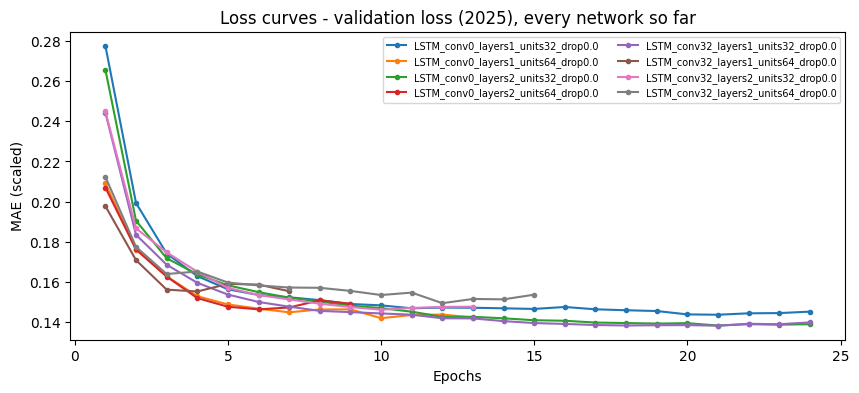

In [9]:
# loss curves - one line per network: the validation loss (2025) after every epoch
plt.figure(figsize=(10, 4))
for name in histories:
    val_loss = histories[name]["val_loss"]
    plt.plot(range(1, len(val_loss) + 1), val_loss, marker="o", markersize=3, label=name)
plt.title("Loss curves - validation loss (2025), every network so far")
plt.xlabel("Epochs")
plt.ylabel("MAE (scaled)")
plt.legend(fontsize=7, ncol=2)
plt.show()

### Round 2: your move
Look at Round 1 before you change anything. Did the convolution help or hurt? Did the second layer pay off? Did the
bigger networks win, or did they overfit (a curve that bottoms out early and turns back up)? Then head in the direction
that worked. The grid below is only a starting point: it keeps the convolution and tries a GRU against an LSTM at 64
units, with and without a little dropout. Change it to follow your own hunch, and run it again as many times as you
like: every network lands on the same leaderboard, and repeats are skipped.

A difference of a few MW on 2025 may be luck. A big one is worth having. **Class challenge:** who gets the lowest 2025
error? Bring your number, and your network, to class.

In [10]:
ROUND_2 = {
    "conv_filters": [32],
    "past_layers": [1],
    "units": [64],
    "cell": ["LSTM", "GRU"],
    "dropout": [0.0, 0.2],
}
leaderboard = try_networks(ROUND_2, "round 2")
leaderboard

LSTM_conv32_layers1_units64_drop0.0 is already on your leaderboard


LSTM_conv32_layers1_units64_drop0.2: 163.9 MW on 2025 (6 epochs, 64 s)


GRU_conv32_layers1_units64_drop0.0: 88.9 MW on 2025 (15 epochs, 154 s)   NEW BEST, 1.5 MW better than the old best


GRU_conv32_layers1_units64_drop0.2: 156.2 MW on 2025 (7 epochs, 68 s)


,round,network,valid_mae_mw (2025),epochs,params,seconds,conv_filters,past_layers,units,cell,dropout
0,round 2,GRU_conv32_layers1_units64_drop0.0,88.9,15,46657,154,32,1,64,GRU,0.0
1,round 1,LSTM_conv0_layers2_units32_drop0.0,90.4,24,22945,451,0,2,32,LSTM,0.0
2,round 1,LSTM_conv32_layers1_units32_drop0.0,90.4,24,18657,224,32,1,32,LSTM,0.0
3,round 1,LSTM_conv0_layers1_units64_drop0.0,92.8,13,53825,195,0,1,64,LSTM,0.0
4,round 1,LSTM_conv0_layers1_units32_drop0.0,94.0,24,14625,252,0,1,32,LSTM,0.0
5,round 1,LSTM_conv32_layers2_units32_drop0.0,95.6,13,26977,168,32,2,32,LSTM,0.0
6,round 1,LSTM_conv0_layers2_units64_drop0.0,95.7,9,86849,374,0,2,64,LSTM,0.0
7,round 1,LSTM_conv32_layers2_units64_drop0.0,97.7,15,94593,270,32,2,64,LSTM,0.0
8,round 1,LSTM_conv32_layers1_units64_drop0.0,101.6,7,61569,99,32,1,64,LSTM,0.0
9,round 2,GRU_conv32_layers1_units64_drop0.2,156.2,7,46657,68,32,1,64,GRU,0.2


## Part 5 · The champion on 2026 (the holdout)
The top of your tuning leaderboard (the lowest 2025 error, from any round) wins. Want a different one? Uncomment the second line (for example a smaller
network that is almost as good). Only now do we look at 2026, next to the Part 1 network and "same hour yesterday".

In [11]:
CHAMPION = leaderboard.iloc[0]["network"]
# CHAMPION = "LSTM_conv32_layers1_units32_drop0.0"       # <-- uncomment to override with any name on your leaderboard

model = networks[CHAMPION]
pred_test = model.predict([X_past_test, X_future_test], verbose=0) * card["load_std"] + card["load_mean"]
part1_pred = networks["LSTM_conv0_layers1_units64_drop0.0"].predict([X_past_test, X_future_test], verbose=0) * card["load_std"] + card["load_mean"]

champion_blocks = mae_by_block(np.abs(pred_test - actual_test))
part1_blocks = mae_by_block(np.abs(part1_pred - actual_test))
rows = []
skills = []
part1_skills = []
for name in champion_blocks:
    skill = 1 - champion_blocks[name] / baseline_blocks[name]
    skills.append(skill)
    part1_skills.append(1 - part1_blocks[name] / baseline_blocks[name])
    rows.append({"lead block": name, "same hour yesterday: avg error (MW)": round(baseline_blocks[name]),
                 "Part 1 network: avg error (MW)": round(part1_blocks[name]),
                 "champion: avg error (MW)": round(champion_blocks[name]), "champion skill": round(skill, 3)})
print("champion:", CHAMPION)
print("average skill on 2026 | champion:", round(float(np.mean(skills)), 3), "| Part 1 network:", round(float(np.mean(part1_skills)), 3))
pd.DataFrame(rows)

champion: GRU_conv32_layers1_units64_drop0.0
average skill on 2026 | champion: 0.585 | Part 1 network: 0.558


,lead block,same hour yesterday: avg error (MW),Part 1 network: avg error (MW),champion: avg error (MW),champion skill
0,1-6 h,266,116,108,0.595
1,7-12 h,266,119,113,0.576
2,13-18 h,266,118,112,0.580
3,19-24 h,266,118,110,0.588


## Part 6 · Look at it: actual vs. predicted, and the holdout over time
Numbers hide a lot. Two pictures of the champion on 2026, with the weather that actually happened (so these are a little
optimistic; the cloud only has forecasts):

1. **Actual vs. predicted.** Every dot is one forecast hour. On the diagonal = perfect. Left: 1 hour ahead. Right: 24
   hours ahead. A cloud that bends away from the diagonal at the top means the model misses the peaks.

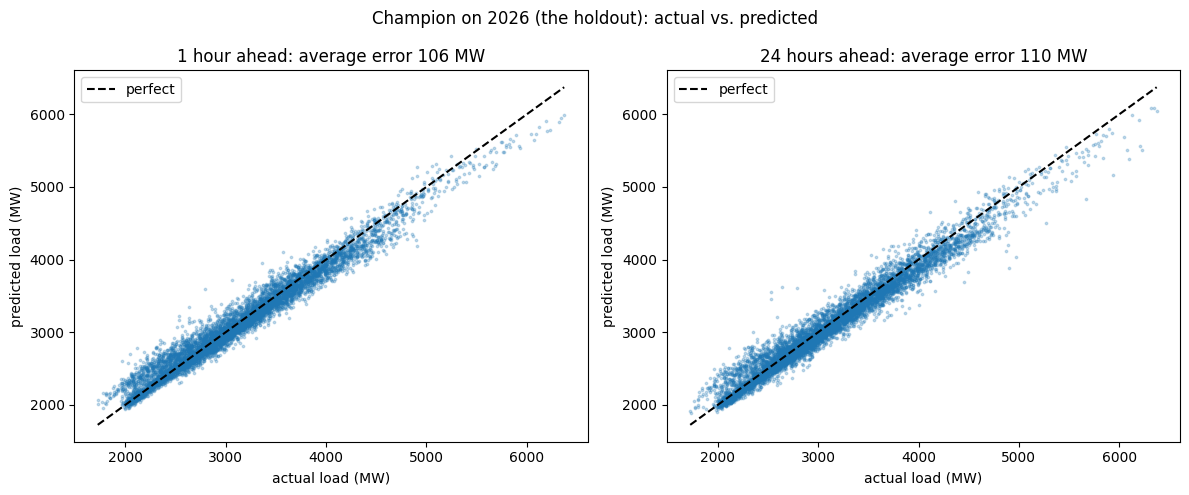

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for panel, lead in [(0, 1), (1, 24)]:
    actual_lead = actual_test[:, lead - 1]
    pred_lead = pred_test[:, lead - 1]
    ax[panel].scatter(actual_lead, pred_lead, s=3, alpha=0.25)
    low = float(min(actual_lead.min(), pred_lead.min()))
    high = float(max(actual_lead.max(), pred_lead.max()))
    ax[panel].plot([low, high], [low, high], "k--", label="perfect")
    ax[panel].set_xlabel("actual load (MW)")
    ax[panel].set_ylabel("predicted load (MW)")
    mae = float(np.mean(np.abs(pred_lead - actual_lead)))
    ax[panel].set_title(f"{lead} hour{'s' if lead > 1 else ''} ahead: average error {mae:.0f} MW")
    ax[panel].legend()
fig.suptitle("Champion on 2026 (the holdout): actual vs. predicted")
plt.tight_layout()
plt.show()

2. **The holdout over time.** The cloud forecasts every hour, but to draw one clean line we take the forecast issued at
   **6 AM Connecticut time** each day and keep its next 24 hours: a day-ahead forecast for every hour of 2026. Top: the
   whole holdout. Bottom: the hottest week, where the money is.

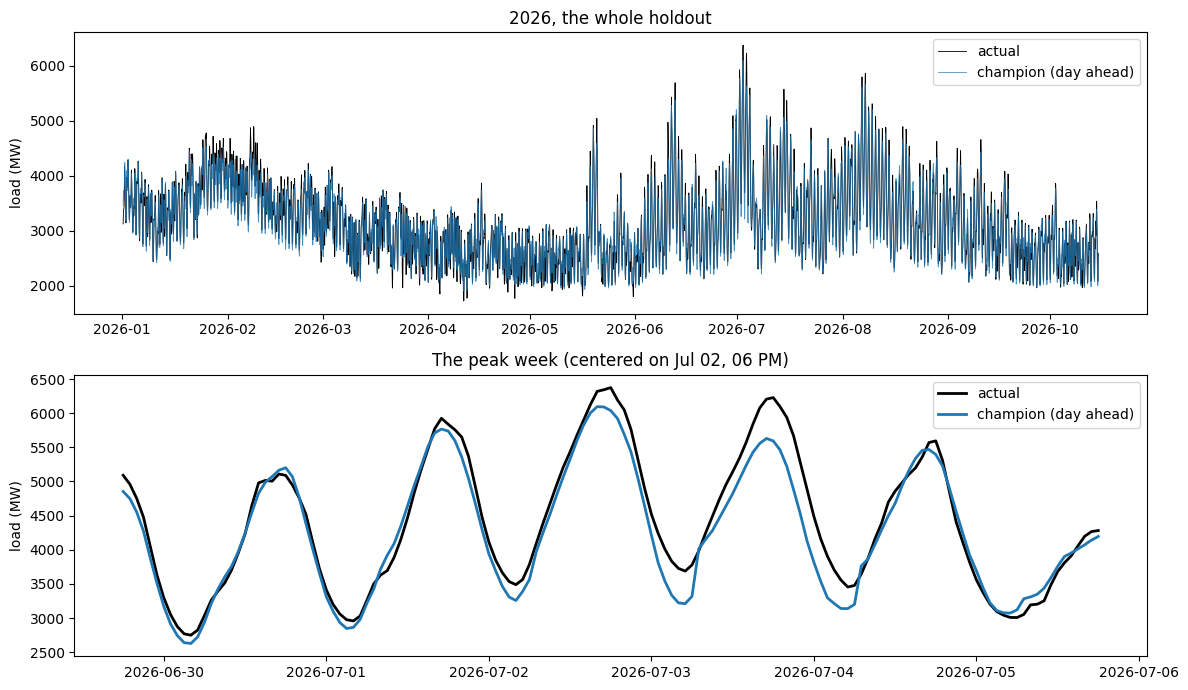

average error of these day-ahead forecasts: 112.6 MW


In [13]:
issue_local = issue_hours_test.tz_convert("America/New_York")
stitched_hours = []
stitched_actual = []
stitched_pred = []
for k in np.where(issue_local.hour == 6)[0]:
    target_hours = pd.date_range(issue_hours_test[k] + pd.Timedelta(hours=1), periods=horizon, freq="h")
    stitched_hours.extend(target_hours)
    stitched_actual.extend(actual_test[k])
    stitched_pred.extend(pred_test[k])
holdout = pd.DataFrame({"actual": stitched_actual, "champion": stitched_pred},
                       index=pd.DatetimeIndex(stitched_hours).tz_convert("America/New_York"))
holdout = holdout[~holdout.index.duplicated()]

fig, ax = plt.subplots(2, 1, figsize=(12, 7))
ax[0].plot(holdout.index, holdout["actual"], color="black", linewidth=0.6, label="actual")
ax[0].plot(holdout.index, holdout["champion"], color="tab:blue", linewidth=0.6, alpha=0.8, label="champion (day ahead)")
ax[0].set_title("2026, the whole holdout")
ax[0].set_ylabel("load (MW)")
ax[0].legend()
peak = holdout["actual"].idxmax()
week = holdout.loc[peak - pd.Timedelta(days=3):peak + pd.Timedelta(days=3)]
ax[1].plot(week.index, week["actual"], color="black", linewidth=2, label="actual")
ax[1].plot(week.index, week["champion"], color="tab:blue", linewidth=2, label="champion (day ahead)")
ax[1].set_title("The peak week (centered on " + peak.strftime("%b %d, %I %p") + ")")
ax[1].set_ylabel("load (MW)")
ax[1].legend()
plt.tight_layout()
plt.show()
print("average error of these day-ahead forecasts:", round(float((holdout["champion"] - holdout["actual"]).abs().mean()), 1), "MW")

## Part 7 · Save it for the cloud
Same files as Part 1: the champion as `model.keras` and a model card with the same scaling numbers (it uses the same
inputs, so `forecast-24h-dl` needs nothing else). The card also records which network won.

In [14]:
card["range_method"] = "none"
card["trained_at"] = pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%dT%H:%M:%SZ")
card["test_skill_2026"] = round(float(np.mean(skills)), 3)
card["test_mae_mw"] = round(float(np.mean(np.abs(pred_test - actual_test))), 1)     # the leaderboard's "Test-year MAE"
card["tuned_network"] = CHAMPION
card["valid_mae_mw_2025"] = float(leaderboard.loc[leaderboard["network"] == CHAMPION, "valid_mae_mw (2025)"].iloc[0])
model.save("model.keras")
with open("model_card.json", "w") as f:
    json.dump(card, f, indent=1)

reloaded = keras.models.load_model("model.keras")
check = reloaded.predict([X_past_test[:5], X_future_test[:5]], verbose=0) * card["load_std"] + card["load_mean"]
print("reloaded model reproduces the predictions:", bool(np.allclose(check, pred_test[:5], atol=0.5)))
print("saved: model.keras and model_card.json for", CHAMPION)

reloaded model reproduces the predictions: True
saved: model.keras and model_card.json for GRU_conv32_layers1_units64_drop0.0


**Ship it only if it's better.** Compare the champion's 2026 skill with your Part 1 network's (Part 5). If the champion
wins, Part 8 replaces your live model; the old one stays in `energy/models/history/`. You are already on the
leaderboard (Part 9 of Part 1), so nothing else changes.

## Part 8 · Ship it to your energy project
Your energy project on Google Cloud (built once with the
[Energy Project Setup Guide](https://colab.research.google.com/github/drdave-teaching/OPIM5509-notebooks/blob/main/FinalProject/Energy_Project_Setup_5509.ipynb)) runs **`forecast-24h-dl`** every hour at :20. It loads
`energy/models/model.keras` and `model_card.json` from your bucket, builds the two inputs with the same `make_inputs` as
this notebook (the last week of live load from your `scraper-isone`, and the newest HRRR weather forecasts from
Dr. Dave's class file, or the National Weather Service forecast your `scraper-weather-forecast` saves if that file is
ever missing), and writes the next 24 hours to `energy/forecasts/latest.csv`.

**Once, before the first deploy:** on your `energy-forecasting-dl` fork, Actions > "Deploy forecast-24h-dl" > Run
workflow (Step 9 of the setup guide). Run it again after every **Sync fork**.

**Deep learning only.** The forecast that goes live must come from `model.predict` on a **Keras network you trained**
(LSTM, GRU, Conv1D, Dense, Bidirectional, or a stack of them), saved as `model.keras` and run by `forecast-24h-dl`.
**Keras models only:** no scikit-learn, gradient boosting, random or quantile forests, XGBoost, statsmodels or
hand-written rules in production (they are fine as a baseline in your report). An ensemble is fine if it is one Keras model (several networks averaged inside one `model.keras`).
You may change `make_inputs` in the cloud function (keep it the same as your notebook), but not how the forecast is
made. The 5509 leaderboard only scores forecasts made by `forecast-24h-dl` with a Keras network: it reads the
`run_summary.json` that the function writes every hour, which lists your network's layers.

Type your project ID, set `UPLOAD = True`, and run the cells below. When the **"Allow access"** pop-up opens,
pick the **Gmail you used for Google Cloud**.

In [15]:
PROJECT_ID = "YOUR-ENERGY-PROJECT-ID"
BUCKET_NAME = PROJECT_ID              # your bucket has the same name as your project (setup guide)
UPLOAD = False                       # True once your energy project is set up

if UPLOAD and ("YOUR-ENERGY-PROJECT-ID" in PROJECT_ID or "YOUR-ENERGY-PROJECT-ID" in BUCKET_NAME):
    print("Type your PROJECT_ID and BUCKET_NAME above, then re-run this cell.")
    UPLOAD = False

if UPLOAD:
    from google.colab import auth
    from google.cloud import storage
    auth.authenticate_user()

    # CHECK 1: which Google account did you just pick in the pop-up?
    account_lines = !gcloud config get-value account
    signed_in_as = "unknown"
    if len(account_lines) > 0:
        signed_in_as = account_lines[-1].strip()
    print("1. Signed in as:", signed_in_as)

    # CHECK 2: can that account see your bucket?
    client = storage.Client(project=PROJECT_ID)
    bucket = client.bucket(BUCKET_NAME)
    try:
        bucket_ok = bucket.exists()
    except Exception as err:
        bucket_ok = False
        print("   Google says:", str(err)[:200])
    if not bucket_ok:
        raise RuntimeError("The account " + signed_in_as + " cannot see the bucket " + BUCKET_NAME + ". "
                           "Check BUCKET_NAME, or Runtime > Disconnect and delete runtime, then run again "
                           "and pick your Google Cloud Gmail in the pop-up.")
    print("2. Bucket found:", BUCKET_NAME)

    # CHECK 3: is forecast-24h-dl deployed?
    state_lines = !gcloud functions describe forecast-24h-dl --gen2 --region=us-central1 --project={PROJECT_ID} --format="value(state)"
    state = "NOT FOUND"
    if len(state_lines) > 0 and state_lines[-1].strip() in ["ACTIVE", "DEPLOYING", "FAILED"]:
        state = state_lines[-1].strip()
    print("3. forecast-24h-dl:", state)
    if state != "ACTIVE":
        print("   Run 'Deploy forecast-24h-dl' on your fork's Actions tab, wait for green, then re-run this cell.")
else:
    print("UPLOAD is False: nothing is uploaded (the model is saved in this Colab session only).")

UPLOAD is False: nothing is uploaded (the model is saved in this Colab session only).


**Upload.** `energy/models/model.keras` is the **live** model (replaced every time you ship);
`energy/models/history/` keeps a copy of every model you ever shipped, named by time.

In [16]:
if UPLOAD:
    bucket.blob("energy/models/model.keras").upload_from_filename("model.keras")
    bucket.blob("energy/models/model_card.json").upload_from_filename("model_card.json")
    stamp = card["trained_at"].replace(":", "-")
    bucket.blob("energy/models/history/model_" + stamp + ".keras").upload_from_filename("model.keras")
    bucket.blob("energy/models/history/model_card_" + stamp + ".json").upload_from_filename("model_card.json")
    print("Live model:  gs://" + BUCKET_NAME + "/energy/models/model.keras", "| range_method:", card["range_method"])
    print("Kept a copy: gs://" + BUCKET_NAME + "/energy/models/history/model_" + stamp + ".keras")
else:
    print("UPLOAD is False: skipping.")

UPLOAD is False: skipping.


**Run it now.** Normally it runs by itself every hour at :20. This cell starts it right now, then checks your bucket
every 15 seconds and shows the forecast.

In [17]:
if UPLOAD:
    from datetime import datetime, timezone
    started = datetime.now(timezone.utc)
    !gcloud scheduler jobs run forecast-24h-dl-hourly --location=us-central1 --project={PROJECT_ID}
    print("Started forecast-24h-dl. Waiting for your forecast", end="")
    latest_blob = bucket.blob("energy/forecasts/latest.csv")
    ready = False
    for attempt in range(20):                 # every 15 seconds, for up to 5 minutes
        time.sleep(15)
        print(".", end="")
        if latest_blob.exists():
            latest_blob.reload()
            if latest_blob.updated > started:
                ready = True
                break
    print()
    if ready:
        import io
        latest = pd.read_csv(io.BytesIO(latest_blob.download_as_bytes()))
        print(latest[["target_hour_utc", "predicted_low_mw", "predicted_load_mw", "predicted_high_mw", "range_method"]].head(6))
    else:
        print("No new forecast after 5 minutes. Run the log cell below and paste the log into Claude.")
else:
    print("UPLOAD is False: skipping.")

UPLOAD is False: skipping.


**Optional, only for troubleshooting.** `"no_load_data"` means your ISO-NE secrets are missing or the scraper has not
collected a full week yet; `"no_model"` means the upload didn't run; `"bad_card"` explains what the card is missing;
anything with `Error` is worth pasting into Claude. A `range_method` ending in `_nws` means the class HRRR file was
missing, so the National Weather Service forecast was used instead (that's fine).

In [18]:
if UPLOAD:
    !gcloud functions logs read forecast-24h-dl --region=us-central1 --gen2 --limit=20 --project={PROJECT_ID}
else:
    print("UPLOAD is False: no log to read.")

UPLOAD is False: no log to read.


## Your turn
* **Round 3, 4, 5...** Copy the Round 2 cell and keep exploring: 128 units, 3 layers, 64 filters, more dropout. Want a
  new knob (a wider `kernel_size`, `recurrent_dropout`, a `Bidirectional` layer on the past week)? Add it to
  `build_network` and `network_name`. Keep each grid small: every value multiplies the time.
* **Sequence length and lags.** A shorter or longer look-back (`lookback_hours` = 48 or 336 in SETTINGS, then re-run
  from Part 2: the card carries it to the cloud). Different lags (say, the load at the same hour last week as an extra
  past column) mean changing `make_inputs`, here **and** in your cloud function.
* **Using Claude?** Good, but read what it writes and test it: check the shapes, keep the "5 random samples match
  make_inputs" check passing, and compare the new network with the old one on the **same 2025 hours** before you ship.
  You have to explain every layer in your report.
* **Keras models only** in production.